**Student Name:** Shelia Howard  
**Course:** DSC680-T302 Applied Data Science (2271-1)  
**Assignment:** Term Project - Milestone 3  
**Due Date:** 10/04/2026  
**Dataset(s):** `FY_2026_Hospital_Readmissions_Reduction_Program_Hospital.csv` from the CMS Provider Data Catalog (dataset 9n3s-kdb3). The notebook first attempts the official CMS direct-download resource and otherwise uses the local file in the notebook directory.

# Hospital Readmission Risk: Classifying Elevated Readmission Performance Under the CMS HRRP

## Introduction

This notebook contains the complete analytical workflow for the hospital readmission project: data acquisition, cleaning, target construction, exploratory analysis, leakage-safe feature preparation, model comparison, grouped cross-validation, out-of-fold evaluation, condition-specific validation, visual exports, and interpretive Q&A.

The central modeling target is **elevated ERR**, defined as `ERR > 1.0`. This is an analytical classification threshold, not the official CMS HRRP payment-reduction calculation.

## Scope Refinement

The initial project scope considered supplementing the HRRP file with Hospital General Information and evaluating a broader model set. The final design narrows the analysis to the FY 2026 HRRP file and two complementary classifiers: logistic regression and random forest. This refinement keeps the analysis focused on a transparent, leakage-safe classification question using variables available consistently in the HRRP file. Hospital-characteristic analysis remains a future extension rather than part of the reported results.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_predict
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_score, recall_score,
    f1_score, balanced_accuracy_score, confusion_matrix,
    ConfusionMatrixDisplay, classification_report
)

pd.set_option('display.max_columns', 100)
RANDOM_STATE = 42
OUTPUT = Path('outputs')
OUTPUT.mkdir(exist_ok=True)

print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('pandas:', pd.__version__)
print('scikit-learn:', sklearn.__version__)

Python: 3.11.16
NumPy: 2.4.6
pandas: 3.0.6
scikit-learn: 1.9.1


### Why this block matters

The imports establish a reproducible, auditable environment. `StratifiedGroupKFold` is especially important because the same hospital can contribute multiple condition records; grouping by Facility ID prevents the same facility from appearing in both training and validation within a fold.

In [2]:
# Load the FY 2026 CMS HRRP resource used for the analysis.
HRRP_URL = (
    'https://data.cms.gov/provider-data/sites/default/files/resources/'
    'a171bc36c488d3e0dc33ec63abb469a6_1770163617/'
    'FY_2026_Hospital_Readmissions_Reduction_Program_Hospital.csv'
)
LOCAL_FILE = Path('FY_2026_Hospital_Readmissions_Reduction_Program_Hospital.csv')

try:
    df_raw = pd.read_csv(HRRP_URL, dtype={'Facility ID': 'string'})
    source_used = 'CMS direct download'
except Exception as exc:
    if not LOCAL_FILE.exists():
        raise FileNotFoundError(
            'The CMS direct resource was unavailable and the expected local source file '
            'FY_2026_Hospital_Readmissions_Reduction_Program_Hospital.csv was not found.'
        ) from exc
    df_raw = pd.read_csv(LOCAL_FILE, dtype={'Facility ID': 'string'})
    source_used = str(LOCAL_FILE)

print('Source:', source_used)
print('Shape:', df_raw.shape)
df_raw.head()

Source: CMS direct download
Shape: (18330, 12)


,Facility Name,Facility ID,State,Measure Name,Number of Discharges,Footnote,Excess Readmission Ratio,Predicted Readmission Rate,Expected Readmission Rate,Number of Readmissions,Start Date,End Date
0,SOUTHEAST HEALTH MEDICAL CENTER,010001,AL,READM-30-HIP-KNEE-HRRP,NaN,NaN,0.9875,4.5734,4.6311,Too Few to Report,07/01/2021,06/30/2024
1,SOUTHEAST HEALTH MEDICAL CENTER,010001,AL,READM-30-CABG-HRRP,137.0,NaN,0.9531,10.3960,10.9078,13,07/01/2021,06/30/2024
2,SOUTHEAST HEALTH MEDICAL CENTER,010001,AL,READM-30-AMI-HRRP,273.0,NaN,0.9370,13.2998,14.1948,33,07/01/2021,06/30/2024
3,SOUTHEAST HEALTH MEDICAL CENTER,010001,AL,READM-30-COPD-HRRP,122.0,NaN,0.9823,16.6384,16.9389,19,07/01/2021,06/30/2024
4,SOUTHEAST HEALTH MEDICAL CENTER,010001,AL,READM-30-PN-HRRP,507.0,NaN,0.9871,15.7529,15.9591,79,07/01/2021,06/30/2024


### Why this block matters

The analysis preserves the original CMS file and performs transformations programmatically. Facility ID is read as text so leading zeroes remain intact. A local-file fallback preserves reproducibility when the direct CMS resource is temporarily unavailable.

In [3]:
df = df_raw.copy()

# Standardize names once so later transformations use consistent identifiers.
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r'[^a-z0-9]+', '_', regex=True)
              .str.strip('_'))

# CMS suppression is missing information, not a numerical zero.
missing_tokens = ['N/A', 'Too Few to Report', 'Not Available', '']
df = df.replace(missing_tokens, np.nan)

numeric_cols = [
    'number_of_discharges', 'excess_readmission_ratio',
    'predicted_readmission_rate', 'expected_readmission_rate',
    'number_of_readmissions'
]
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Derive a compact condition label and create the target only when ERR is observed.
df['condition'] = (df['measure_name']
                   .str.replace('READM-30-', '', regex=False)
                   .str.replace('-HRRP', '', regex=False))
df['elevated_err'] = np.where(
    df['excess_readmission_ratio'].notna(),
    (df['excess_readmission_ratio'] > 1.0).astype(int),
    np.nan
)

duplicate_count = int(df.duplicated().sum())
if duplicate_count:
    df = df.drop_duplicates().copy()

print(f'Exact duplicate rows: {duplicate_count}')
print(f'Rows after duplicate check: {len(df):,}')
print(f'Observed ERR rows: {df.excess_readmission_ratio.notna().sum():,}')
print(f'Target prevalence: {df.elevated_err.mean():.4f}')
display(df.isna().mean().sort_values(ascending=False).head(10))

Exact duplicate rows: 0
Rows after duplicate check: 18,330
Observed ERR rows: 11,720
Target prevalence: 0.4815


footnote                      0.618822
number_of_readmissions        0.561538
number_of_discharges          0.550355
expected_readmission_rate     0.360611
excess_readmission_ratio      0.360611
predicted_readmission_rate    0.360611
elevated_err                  0.360611
measure_name                  0.000000
facility_name                 0.000000
facility_id                   0.000000
dtype: float64

### Why this block matters

Suppressed values are retained as missing rather than fabricated, exact duplicates are checked, naming conventions are standardized, and the target is defined only where CMS reports ERR. The executed analysis found no exact duplicate rows and 11,720 usable outcomes.

,elevated_share,n
condition,,
CABG,0.498861,878
AMI,0.496544,1736
HF,0.489126,2621
HIP-KNEE,0.478922,1447
COPD,0.472234,2323
PN,0.468140,2715


,mean,count
state,,
NJ,0.654412,272
MA,0.625000,240
MS,0.610811,185
IL,0.578411,491
FL,0.574578,771
GA,0.557803,346
CA,0.552023,1038
KY,0.541850,227
WV,0.536842,95


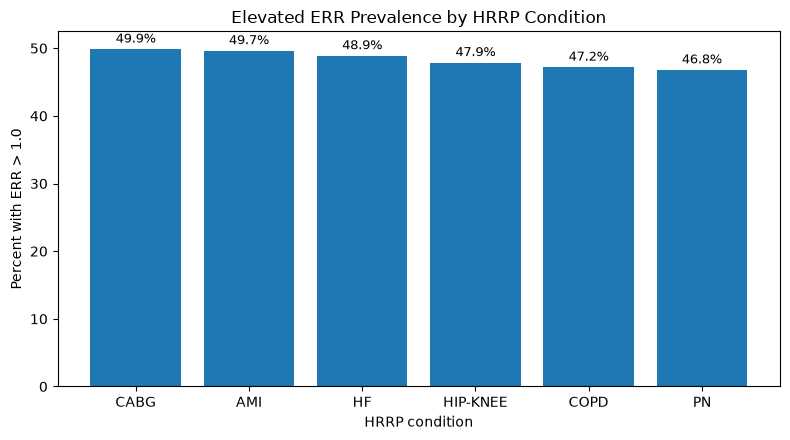

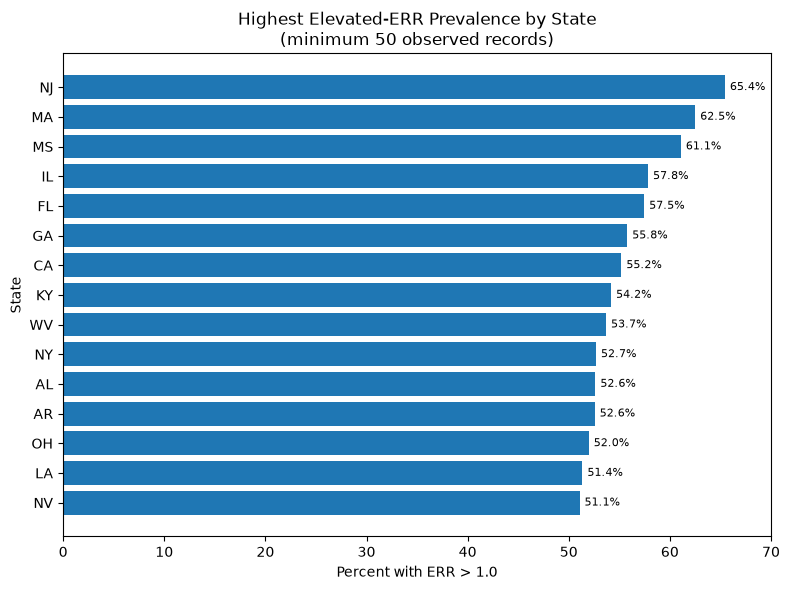

Lowest qualifying state:            mean  count
state                 
MT     0.188679     53


In [4]:
# Descriptive summaries answer Research Question 1 without treating differences as causal rankings.
eda = df[df['elevated_err'].notna()].copy()
condition_summary = (eda.groupby('condition')['elevated_err']
                     .agg(['mean', 'count'])
                     .rename(columns={'mean': 'elevated_share', 'count': 'n'})
                     .sort_values('elevated_share', ascending=False))
state_summary = (eda.groupby('state')['elevated_err']
                 .agg(['mean', 'count'])
                 .query('count >= 50')
                 .sort_values('mean', ascending=False))

display(condition_summary)
display(state_summary.head(15))


# Plot condition-level prevalence and label each bar for direct interpretation.
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(condition_summary.index, condition_summary['elevated_share'] * 100)
ax.set_ylabel('Percent with ERR > 1.0')
ax.set_xlabel('HRRP condition')
ax.set_title('Elevated ERR Prevalence by HRRP Condition')
ax.set_ylim(0, 52.5)
for bar, value in zip(bars, condition_summary['elevated_share'] * 100):
    ax.text(bar.get_x() + bar.get_width()/2, value + 0.5, f'{value:.1f}%',
            ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUT / 'condition_prevalence.png', dpi=200, bbox_inches='tight')
plt.show()

# Plot the 15 highest state-level prevalence estimates among states with at least 50 observed records.
state_plot = state_summary.head(15).sort_values('mean')
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.barh(state_plot.index, state_plot['mean'] * 100)
ax.set_xlabel('Percent with ERR > 1.0')
ax.set_ylabel('State')
ax.set_title('Highest Elevated-ERR Prevalence by State\n(minimum 50 observed records)')
ax.set_xlim(0, 70)
for bar, value in zip(bars, state_plot['mean'] * 100):
    ax.text(value + 0.5, bar.get_y() + bar.get_height()/2, f'{value:.1f}%',
            va='center', fontsize=8)
plt.tight_layout()
plt.savefig(OUTPUT / 'state_prevalence.png', dpi=200, bbox_inches='tight')
plt.show()

print('Lowest qualifying state:', state_summary.tail(1))


### Why this block matters

The condition distribution is narrow, while state variation is much wider. These are descriptive associations only. State differences are not interpreted as causal quality rankings because the public file does not contain every clinical, social, organizational, or community factor that may affect readmission performance.

In [5]:
# Restrict predictors to non-leaking variables established in the project design.
model_df = df[df['elevated_err'].notna()].copy()
X = model_df[['condition', 'state', 'number_of_discharges']]
y = model_df['elevated_err'].astype(int)
groups = model_df['facility_id']

categorical = ['condition', 'state']
numeric = ['number_of_discharges']

preprocess = ColumnTransformer([
    ('cat', Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical),
    ('num', Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler())
    ]), numeric)
])

models = {
    'Logistic regression': LogisticRegression(
        max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE
    ),
    'Random forest': RandomForestClassifier(
        n_estimators=400, min_samples_leaf=5,
        class_weight='balanced_subsample', random_state=RANDOM_STATE, n_jobs=-1
    )
}

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'roc_auc': 'roc_auc', 'pr_auc': 'average_precision', 'precision': 'precision',
    'recall': 'recall', 'f1': 'f1', 'balanced_accuracy': 'balanced_accuracy'
}

rows = []
for name, model in models.items():
    pipe = Pipeline([('prep', preprocess), ('model', model)])
    res = cross_validate(pipe, X, y, groups=groups, cv=cv, scoring=scoring, n_jobs=-1)
    row = {'model': name}
    for metric in scoring:
        row[metric] = res[f'test_{metric}'].mean()
        row[f'{metric}_sd'] = res[f'test_{metric}'].std()
    rows.append(row)

results = (pd.DataFrame(rows).set_index('model').sort_values('roc_auc', ascending=False))
display(results.round(3))

,roc_auc,roc_auc_sd,pr_auc,pr_auc_sd,precision,precision_sd,recall,recall_sd,f1,f1_sd,balanced_accuracy,balanced_accuracy_sd
model,,,,,,,,,,,,
Random forest,0.663,0.011,0.654,0.012,0.592,0.007,0.577,0.017,0.584,0.010,0.604,0.007
Logistic regression,0.607,0.009,0.570,0.015,0.545,0.006,0.678,0.034,0.604,0.012,0.576,0.005


### Why this block matters

The design directly tests the second research question while avoiding target leakage. Random forest is the stronger ranking model by the predeclared primary metric, ROC-AUC. Logistic regression has higher recall and F1 at the default threshold, demonstrating that model selection depends on the operational objective rather than a single score.

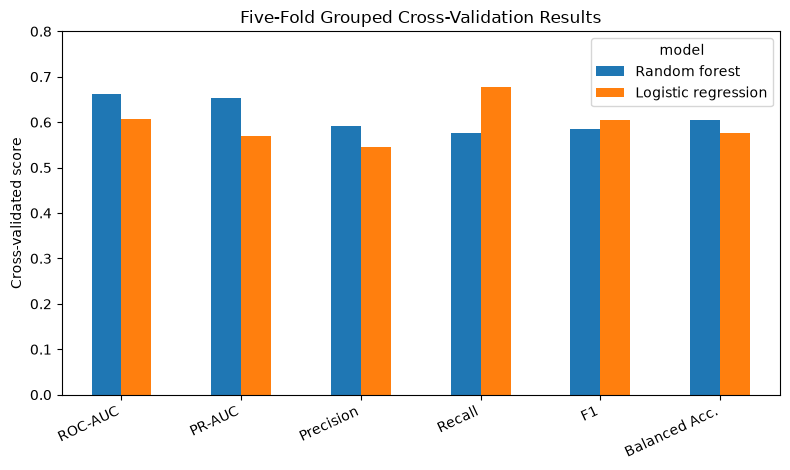

In [6]:
# Visualize the mean cross-validated model metrics reported in the white paper.
metric_order = ['roc_auc', 'pr_auc', 'precision', 'recall', 'f1', 'balanced_accuracy']
metric_labels = ['ROC-AUC', 'PR-AUC', 'Precision', 'Recall', 'F1', 'Balanced Acc.']

plot_df = results.loc[['Random forest', 'Logistic regression'], metric_order].T
ax = plot_df.plot(kind='bar', figsize=(8, 4.8))
ax.set_ylabel('Cross-validated score')
ax.set_xlabel('')
ax.set_title('Five-Fold Grouped Cross-Validation Results')
ax.set_xticklabels(metric_labels, rotation=25, ha='right')
ax.set_ylim(0, 0.8)
plt.tight_layout()
plt.savefig(OUTPUT / 'model_performance.png', dpi=200, bbox_inches='tight')
plt.show()


### Why this block matters

This visualization summarizes the model tradeoff: random forest leads on ROC-AUC, PR-AUC, precision, and balanced accuracy, while logistic regression leads on recall and F1 at the default threshold. Fold-level standard deviations remain in the `results` table so the comparison is not interpreted from point estimates alone.

Random forest
              precision    recall  f1-score   support

           0      0.616     0.632     0.624      6077
           1      0.592     0.577     0.584      5643

    accuracy                          0.605     11720
   macro avg      0.604     0.604     0.604     11720
weighted avg      0.605     0.605     0.605     11720

Confusion matrix: [[3838 2239]
 [2389 3254]]


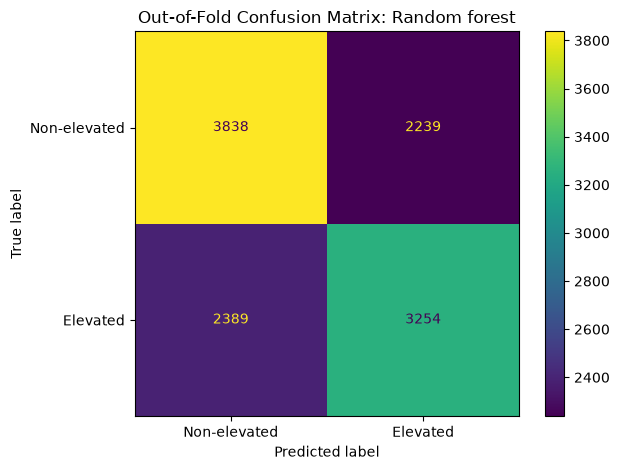

In [7]:
# Generate out-of-fold predictions so every record is evaluated by a model that did not train on its fold.
best_name = results.index[0]
best_model = models[best_name]
best_pipe = Pipeline([('prep', preprocess), ('model', best_model)])

oof_pred = cross_val_predict(best_pipe, X, y, groups=groups, cv=cv, method='predict', n_jobs=-1)
oof_prob = cross_val_predict(best_pipe, X, y, groups=groups, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]

print(best_name)
print(classification_report(y, oof_pred, digits=3))
cm = confusion_matrix(y, oof_pred)
print('Confusion matrix:', cm)

disp = ConfusionMatrixDisplay(cm, display_labels=['Non-elevated', 'Elevated'])
disp.plot(values_format='d')
plt.title(f'Out-of-Fold Confusion Matrix: {best_name}')
plt.tight_layout()
plt.savefig(OUTPUT / 'confusion_matrix.png', dpi=200, bbox_inches='tight')
plt.show()


### Why this block matters

The confusion matrix translates abstract scores into review workload. At the default threshold, the random forest produces 2,239 false positives and 2,389 false negatives. That error volume is too large for automated decisions and supports the project's recommendation that predictions be used only as a human-reviewed prioritization queue.

,condition,n,roc_auc,pr_auc,recall,f1
0,AMI,1736,0.698,0.709,0.607,0.620
5,PN,2715,0.674,0.645,0.571,0.584
2,COPD,2323,0.673,0.660,0.594,0.592
1,CABG,878,0.656,0.706,0.482,0.551
3,HF,2621,0.641,0.625,0.621,0.598
4,HIP-KNEE,1447,0.592,0.587,0.499,0.520


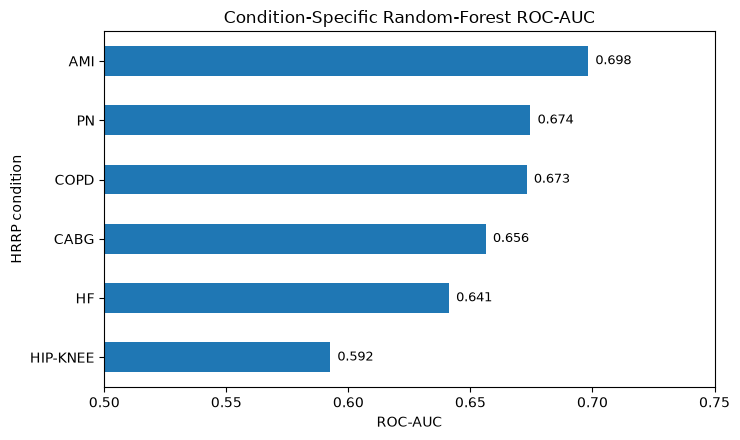

In [8]:
# Evaluate the selected model separately by HRRP condition.
check = model_df[['condition']].copy()
check['y_true'] = y.values
check['prob'] = oof_prob
check['pred'] = (oof_prob >= 0.5).astype(int)

by_condition = []
for cond, g in check.groupby('condition'):
    if g['y_true'].nunique() < 2:
        continue
    by_condition.append({
        'condition': cond,
        'n': len(g),
        'roc_auc': roc_auc_score(g['y_true'], g['prob']),
        'pr_auc': average_precision_score(g['y_true'], g['prob']),
        'recall': recall_score(g['y_true'], g['pred']),
        'f1': f1_score(g['y_true'], g['pred'])
    })

by_condition = pd.DataFrame(by_condition).sort_values('roc_auc', ascending=False)
display(by_condition.round(3))

plot_auc = by_condition.sort_values('roc_auc')
ax = plot_auc.plot(
    x='condition', y='roc_auc', kind='barh', legend=False, figsize=(7.5, 4.5)
)
ax.set_xlim(0.5, 0.75)
ax.set_xlabel('ROC-AUC')
ax.set_ylabel('HRRP condition')
ax.set_title('Condition-Specific Random-Forest ROC-AUC')
for patch, value in zip(ax.patches, plot_auc['roc_auc']):
    ax.text(value + 0.003, patch.get_y() + patch.get_height()/2, f'{value:.3f}',
            va='center', fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUT / 'condition_auc.png', dpi=200, bbox_inches='tight')
plt.show()


### Why this block matters

This section answers the third research question. The pooled ROC-AUC hides meaningful subgroup variation. Hip/knee replacement is much closer to chance-level ranking than AMI, so any real implementation would need condition-specific monitoring and possibly different modeling strategies by condition.

In [9]:
# Export analytical result tables for reproducibility and reporting.
condition_summary.to_csv(OUTPUT / 'condition_summary.csv')
state_summary.to_csv(OUTPUT / 'state_summary.csv')
results.to_csv(OUTPUT / 'model_validation_results.csv')
by_condition.to_csv(OUTPUT / 'condition_validation_results.csv', index=False)

project_summary = {
    'rows_raw': int(len(df_raw)),
    'rows_with_observed_err': int(df['excess_readmission_ratio'].notna().sum()),
    'unique_facilities': int(df['facility_id'].nunique()),
    'model_rows': int(len(model_df)),
    'target_prevalence': float(y.mean()),
    'selected_model': best_name
}
print(project_summary)
expected_figures = [
    'condition_prevalence.png', 'state_prevalence.png',
    'model_performance.png', 'confusion_matrix.png', 'condition_auc.png'
]
print('Saved outputs to:', OUTPUT.resolve())
print('Expected figure exports:', expected_figures)


{'rows_raw': 18330, 'rows_with_observed_err': 11720, 'unique_facilities': 3055, 'model_rows': 11720, 'target_prevalence': 0.48148464163822524, 'selected_model': 'Random forest'}
Saved outputs to: C:\Users\socia\dsc680\outputs
Expected figure exports: ['condition_prevalence.png', 'state_prevalence.png', 'model_performance.png', 'confusion_matrix.png', 'condition_auc.png']


### Why this block matters

Exporting the result tables preserves traceability from the analytical workflow to reported results. The executed analysis contains 3,055 unique facilities and 11,720 modeled hospital-condition observations. Keeping analytical outputs separate from presentation formatting also reduces transcription errors.

## Model-Selection Boundary

Hyperparameter tuning and probability calibration are not included in the current model. This is deliberate: the analysis emphasizes leakage prevention, grouped validation, transparent model comparison, and honest interpretation of modest discrimination. Calibration and future-period validation remain necessary extensions before operational use.

## Ethical and Deployment Boundaries

- ERR is an HRRP performance measure, not a causal estimate of care quality.
- Suppressed outcomes remain missing and are not imputed.
- The dataset is hospital-level, so patient privacy risk is low relative to reputational, fairness, and data-validity risks.
- High-risk flags are interpreted as prompts for **human review of hospital-condition combinations**, not automatic patient-level interventions.
- The model does **not** reproduce the CMS HRRP payment-adjustment calculation and is not used as a penalty or savings calculator.
- A future production design would require time-aware validation, calibration, threshold governance, condition-specific monitoring, and rollback criteria.

## Project Q&A

1. **Why is ERR > 1.0 the classification threshold?** It is a transparent analytical definition of elevated readmission performance because predicted readmissions exceed expected readmissions at values above 1.0. It is not the official HRRP payment-reduction rule.
2. **Why were predicted/expected rates and readmission count excluded?** They directly determine or closely track the same-period outcome and would create target leakage.
3. **How were suppressed values handled?** Suppression tokens were converted to missing; suppressed ERR outcomes were excluded from supervised modeling rather than imputed.
4. **Why group cross-validation by Facility ID?** Hospitals contribute multiple condition records, so grouping prevents the same facility from leaking across training and validation within a fold.
5. **Why does random forest lead on ROC-AUC while logistic regression leads on recall/F1?** ROC-AUC measures ranking across thresholds; recall and F1 depend on the selected threshold. The models therefore represent different operational tradeoffs.
6. **Which condition has the highest elevated-ERR prevalence?** CABG, approximately 49.9% in the analyzed FY 2026 file.
7. **Why is hip/knee discrimination weaker?** The analysis establishes weaker performance but not a cause. The restricted non-leaking predictors provide less separation for this subgroup.
8. **How is a high-risk flag interpreted?** The hospital-condition combination enters a human-reviewed quality queue for investigation of trends and operational context. The flag is not a patient-level intervention recommendation.
9. **What fairness or reputational risks arise from public rankings?** Rankings can be misread as causal judgments about quality despite unmeasured population and structural differences. The analysis therefore avoids best/worst labels.
10. **What changes are needed for true future-period prediction?** A stronger design would align historical HRRP releases, train on earlier periods, validate on later periods, calibrate probabilities, set an operational threshold, and evaluate on a final untouched future release.

## Conclusion

The analysis demonstrates a complete, leakage-aware data science workflow using public CMS HRRP data. Random forest is the stronger pooled ranking model (ROC-AUC 0.663), while logistic regression achieves higher recall at the default threshold. The result is best interpreted as modest screening signal rather than a high-accuracy decision system.

The technical design and operational recommendation point in the same direction: grouped validation, explicit leakage prevention, subgroup analysis, and the out-of-fold error pattern all support a **human-reviewed hospital-condition prioritization queue**. The model does not identify individual high-risk patients and does not calculate CMS payment reductions. A stronger future version would require longitudinal CMS releases, richer non-leaking hospital characteristics, probability calibration, threshold governance, and external future-period validation.

The principal analytical figures are generated directly from the same objects used for reporting: condition prevalence, state prevalence, model comparison, confusion matrix, and condition-specific ROC-AUC.